In [1]:
import argparse
import json
import os
import pathlib

import natsort
import pandas as pd
from timelapse_utils.file_utils.notebook_init_utils import (
    bandicoot_check,
    init_notebook,
)

root_dir, in_notebook = init_notebook()

In [2]:
if in_notebook:
    import tqdm.notebook as tqdm

    plate_name = "plate_2"
else:
    import tqdm

    argparser = argparse.ArgumentParser()

    argparser.add_argument(
        "--plate_name",
        type=str,
        help="Name of the plate to analyze",
    )
    args = argparser.parse_args()
    plate_name = args.plate_name

In [3]:
image_base_dir = bandicoot_check(
    bandicoot_mount_path=pathlib.Path(f"{os.path.expanduser('~')}/mnt/bandicoot/"),
    root_dir=root_dir,
)
image_base_dir = pathlib.Path(f"{image_base_dir}/processed_data")

norm_agg_profiles_path = pathlib.Path(
    f"{image_base_dir}/12.aggregate_profiles/{plate_name}/aggregate_profiles_from_normalized.parquet"
).resolve(strict=True)
norm_consensus_profiles_path = pathlib.Path(
    f"{image_base_dir}/12.aggregate_profiles/{plate_name}/consensus_profiles_from_normalized.parquet"
).resolve(strict=True)
fs_agg_profiles_path = pathlib.Path(
    f"{image_base_dir}/12.aggregate_profiles/{plate_name}/aggregate_profiles_from_feature_selected.parquet"
).resolve()
fs_consensus_profiles_path = pathlib.Path(
    f"{image_base_dir}/12.aggregate_profiles/{plate_name}/consensus_profiles_from_feature_selected.parquet"
).resolve()
norm_agg_profiles_path.parent.mkdir(exist_ok=True, parents=True)

In [4]:
norm_agg_df = pd.read_parquet(norm_agg_profiles_path)

In [7]:
norm_agg_df

,Metadata_Well,Metadata_Inducer,Metadata_Inducer_dose,Metadata_Inhibitor,Metadata_Inhibitor_dose,Metadata_unique_cell_id,Metadata_Time,Metadata_Well_FOV,Metadata_FOV,Metadata_Well_FOV_Time,...,Nuclei_Texture_Variance_CL640_3_03_256,Nuclei_Texture_Variance_NucleoLive_3_00_256,Nuclei_Texture_Variance_NucleoLive_3_01_256,Nuclei_Texture_Variance_NucleoLive_3_02_256,Nuclei_Texture_Variance_NucleoLive_3_03_256,Nuclei_Texture_Variance_SYTOXGreen_3_00_256,Nuclei_Texture_Variance_SYTOXGreen_3_01_256,Nuclei_Texture_Variance_SYTOXGreen_3_02_256,Nuclei_Texture_Variance_SYTOXGreen_3_03_256,Metadata_Treatment_combo
0,B2,DMSO,0.15%,DMSO,0.15%,B2_1_1_1,1,B2_1,1,B2_1_1,...,-0.347382,-0.123137,-0.125733,-0.122980,-0.125679,-0.126305,-0.126386,-0.126139,-0.126187,DMSO 0.15% + DMSO 0.15%
1,B2,DMSO,0.15%,DMSO,0.15%,B2_1_2_1,2,B2_1,1,B2_1_2,...,-0.413590,-0.118790,-0.121205,-0.118558,-0.121107,-0.126305,-0.126386,-0.126139,-0.126187,DMSO 0.15% + DMSO 0.15%
2,B2,DMSO,0.15%,DMSO,0.15%,B2_1_3_1,3,B2_1,1,B2_1_3,...,-0.348850,-0.102352,-0.103900,-0.101989,-0.103800,-0.126305,-0.126386,-0.126139,-0.126187,DMSO 0.15% + DMSO 0.15%
3,B2,DMSO,0.15%,DMSO,0.15%,B2_1_4_1,4,B2_1,1,B2_1_4,...,-0.304027,-0.102459,-0.104086,-0.102176,-0.103921,-0.126305,-0.126386,-0.126139,-0.126187,DMSO 0.15% + DMSO 0.15%
4,B2,DMSO,0.15%,DMSO,0.15%,B2_1_5_1,5,B2_1,1,B2_1_5,...,-0.200080,-0.103424,-0.105196,-0.103189,-0.105215,-0.126305,-0.126386,-0.126139,-0.126187,DMSO 0.15% + DMSO 0.15%
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45787,O3,S730,0.0416uM,MCC950,5uM,O3_4_284_1,284,O3_4,4,O3_4_284,...,-0.875415,-0.110165,-0.111578,-0.109339,-0.111358,0.281612,0.289315,0.277913,0.290257,S730 0.0416uM + MCC950 5uM
45788,O3,S730,0.0416uM,MCC950,5uM,O3_4_285_1,285,O3_4,4,O3_4_285,...,-0.875415,-0.117458,-0.119952,-0.117473,-0.119666,0.254744,0.253960,0.254255,0.261824,S730 0.0416uM + MCC950 5uM
45789,O3,S730,0.0416uM,MCC950,5uM,O3_4_286_1,286,O3_4,4,O3_4_286,...,-0.875415,-0.105480,-0.106825,-0.104848,-0.106854,0.306007,0.306653,0.303270,0.303975,S730 0.0416uM + MCC950 5uM
45790,O3,S730,0.0416uM,MCC950,5uM,O3_4_287_1,287,O3_4,4,O3_4_287,...,-0.875415,-0.104872,-0.106513,-0.104704,-0.106125,0.374879,0.389823,0.390971,0.386288,S730 0.0416uM + MCC950 5uM


In [9]:
norm_agg_df["Metadata_Well"].unique()

array(['B2', 'B3', 'B4', 'C2', 'C3', 'C4', 'D2', 'D3', 'D4', 'E2', 'E3',
       'E4', 'F2', 'F3', 'F4', 'G2', 'G3', 'G4', 'H2', 'H3', 'H4', 'I2',
       'I3', 'I4', 'J2', 'J3', 'J4', 'K2', 'K3', 'K4', 'L2', 'L3', 'L4',
       'M2', 'M3', 'M4', 'N2', 'N3', 'O2', 'O3'], dtype=object)

In [8]:
norm_agg_df["Metadata_Inducer"].unique()

array(['DMSO', 'S730', 'uM5856'], dtype=object)

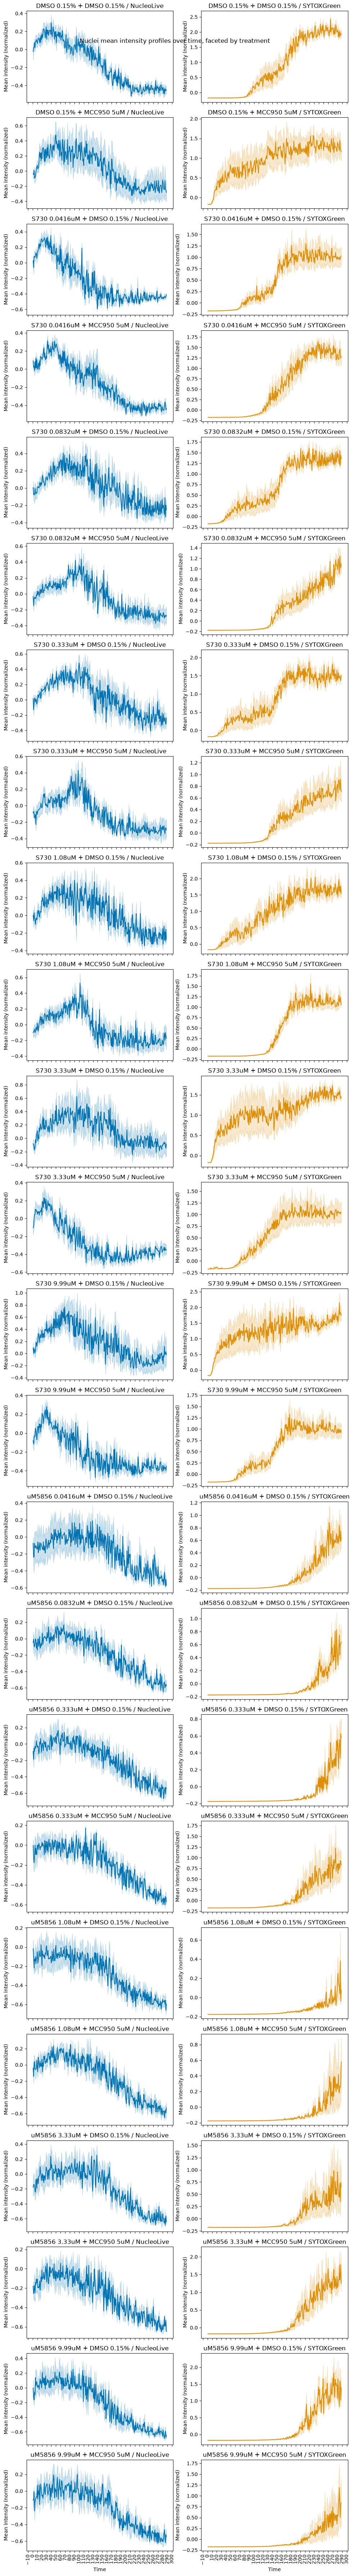

In [5]:
# plot the intensity profiles over time for nuclei, faceted by treatment
import re

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns


def dose_sort_key(treatment: str) -> tuple:
    """Pull the leading numeric dose values out of a treatment combo string for sorting."""
    matches = re.findall(r"([\d.]+)", treatment)
    return tuple(float(m) for m in matches) if matches else (0.0,)


compartment = "Nuclei"
channels = ["NucleoLive", "SYTOXGreen"]

norm_agg_df["Metadata_Treatment_combo"] = (
    norm_agg_df["Metadata_Inducer"].astype(str)
    + " "
    + norm_agg_df["Metadata_Inducer_dose"].astype(str)
    + " + "
    + norm_agg_df["Metadata_Inhibitor"].astype(str)
    + " "
    + norm_agg_df["Metadata_Inhibitor_dose"].astype(str)
)

treatment_order = sorted(
    norm_agg_df["Metadata_Treatment_combo"].unique(), key=dose_sort_key
)
palette = sns.color_palette("colorblind", n_colors=len(channels))

fig, axes = plt.subplots(
    len(treatment_order),
    len(channels),
    figsize=(5 * len(channels), 3 * len(treatment_order)),
    sharex=True,
)
for row_idx, treatment in enumerate(treatment_order):
    treatment_df = norm_agg_df[norm_agg_df["Metadata_Treatment_combo"] == treatment]
    for col_idx, channel in enumerate(channels):
        feature = f"{compartment}_Intensity_MeanIntensity_{channel}"
        ax = axes[row_idx, col_idx]
        if feature not in norm_agg_df.columns:
            ax.set_visible(False)
            continue
        sns.lineplot(
            data=treatment_df,
            x="Metadata_Time",
            y=feature,
            color=palette[col_idx],
            estimator="mean",
            errorbar="se",
            ax=ax,
        )
        ax.set_title(f"{treatment} / {channel}")
        ax.set_xlabel("Time")
        ax.set_ylabel("Mean intensity (normalized)")
        ax.xaxis.set_major_locator(mticker.MultipleLocator(10))
        ax.tick_params(axis="x", rotation=90)

fig.suptitle("Nuclei mean intensity profiles over time, faceted by treatment")
fig.tight_layout()
plt.show()

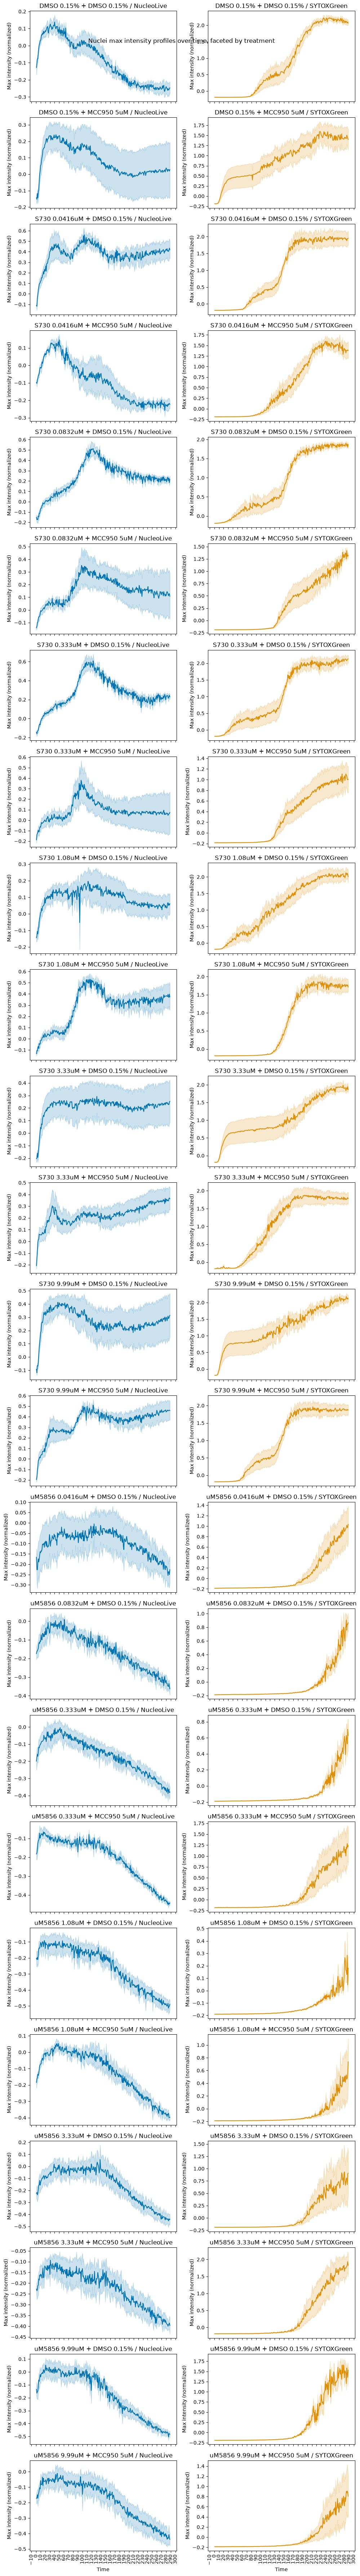

In [6]:
# plot the max intensity profiles over time for nuclei, faceted by treatment
fig, axes = plt.subplots(
    len(treatment_order),
    len(channels),
    figsize=(5 * len(channels), 3 * len(treatment_order)),
    sharex=True,
)
for row_idx, treatment in enumerate(treatment_order):
    treatment_df = norm_agg_df[norm_agg_df["Metadata_Treatment_combo"] == treatment]
    for col_idx, channel in enumerate(channels):
        feature = f"{compartment}_Intensity_MaxIntensity_{channel}"
        ax = axes[row_idx, col_idx]
        if feature not in norm_agg_df.columns:
            ax.set_visible(False)
            continue
        sns.lineplot(
            data=treatment_df,
            x="Metadata_Time",
            y=feature,
            color=palette[col_idx],
            estimator="mean",
            errorbar="se",
            ax=ax,
        )
        ax.set_title(f"{treatment} / {channel}")
        ax.set_xlabel("Time")
        ax.set_ylabel("Max intensity (normalized)")
        ax.xaxis.set_major_locator(mticker.MultipleLocator(10))
        ax.tick_params(axis="x", rotation=90)

fig.suptitle("Nuclei max intensity profiles over time, faceted by treatment")
fig.tight_layout()
plt.show()